In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
import re
import string
from collections import Counter
import urllib.request
import tarfile
import os

# Set random seed for reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [ ]:
# Load pre-tokenized IMDB dataset using Keras (built-in Colab, no external download issues)
import tensorflow as tf

MAX_VOCAB_SIZE = 10000
max_len = 200

print("Loading IMDB dataset from Keras...")
(X_train_seq, y_train_seq), (X_test_seq, y_test_seq) = tf.keras.datasets.imdb.load_data(num_words=MAX_VOCAB_SIZE)

# Pad sequences to constant length
X_train = tf.keras.preprocessing.sequence.pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test = tf.keras.preprocessing.sequence.pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# Create dummy vocabulary mapping index to index
vocab = {str(i): i for i in range(MAX_VOCAB_SIZE)}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 2

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Loading IMDB dataset from Keras...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train shape: (25000, 200)
X_test shape: (25000, 200)


In [ ]:
# Map variables to keep compatibility with downstream cells
train_texts = [" "] * len(X_train)
train_labels = y_train_seq
test_texts = [" "] * len(X_test)
test_labels = y_test_seq

In [ ]:
# Mapping and compatibility initialization
y_train = np.array(train_labels)
y_test = np.array(test_labels)
print("Data alignment complete!")

Data alignment complete!


In [ ]:
class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Ensure we refer to the loaded numpy arrays
BATCH_SIZE = 64
train_dataset = IMDBDataset(X_train, y_train)
test_dataset = IMDBDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Created loaders: {len(train_loader)} train batches, {len(test_loader)} test batches.")

Created loaders: 391 train batches, 391 test batches.


### 2. Implement the Bi-LSTM Architecture in PyTorch

In [ ]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout):
        super(BiLSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim,
                           hidden_dim,
                           num_layers=n_layers,
                           bidirectional=True,
                           dropout=dropout if n_layers > 1 else 0,
                           batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        # text shape: [batch size, sent len]
        embedded = self.dropout(self.embedding(text))
        # embedded shape: [batch size, sent len, emb dim]

        output, (hidden, cell) = self.lstm(embedded)
        # concat the final forward and backward hidden states
        hidden = self.dropout(torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1))
        # hidden shape: [batch size, hid dim * num directions]

        return self.fc(hidden)

### 3. Model Initialization, Training, and Evaluation Loops

In [ ]:
INPUT_DIM = MAX_VOCAB_SIZE
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
OUTPUT_DIM = 1
N_LAYERS = 2
DROPOUT = 0.5

model = BiLSTMClassifier(INPUT_DIM, EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, N_LAYERS, DROPOUT).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss().to(device)

def binary_accuracy(preds, y):
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    acc = correct.sum() / len(correct)
    return acc

In [ ]:
def train(model, iterator, optimizer, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.train()

    for batch in iterator:
        text, labels = batch
        text, labels = text.to(device), labels.to(device)

        optimizer.zero_grad()
        predictions = model(text).squeeze(1)
        loss = criterion(predictions, labels)
        acc = binary_accuracy(predictions, labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.eval()

    with torch.no_grad():
        for batch in iterator:
            text, labels = batch
            text, labels = text.to(device), labels.to(device)

            predictions = model(text).squeeze(1)
            loss = criterion(predictions, labels)
            acc = binary_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [ ]:
N_EPOCHS = 5
best_valid_loss = float('inf')

train_losses, val_losses = [], []

print("Starting model training...")
for epoch in range(N_EPOCHS):
    train_loss, train_acc = train(model, train_loader, optimizer, criterion)
    valid_loss, valid_acc = evaluate(model, test_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(valid_loss)

    print(f'Epoch: {epoch+1:02}')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%')
    print(f'\t Val. Loss: {valid_loss:.3f} |  Val. Acc: {valid_acc*100:.2f}%')

Starting model training...
Epoch: 01
	Train Loss: 0.674 | Train Acc: 57.01%
	 Val. Loss: 0.640 |  Val. Acc: 63.13%
Epoch: 02
	Train Loss: 0.649 | Train Acc: 61.94%
	 Val. Loss: 0.611 |  Val. Acc: 66.18%
Epoch: 03
	Train Loss: 0.647 | Train Acc: 60.86%
	 Val. Loss: 0.590 |  Val. Acc: 70.87%
Epoch: 04
	Train Loss: 0.516 | Train Acc: 74.76%
	 Val. Loss: 0.406 |  Val. Acc: 82.19%
Epoch: 05
	Train Loss: 0.436 | Train Acc: 80.16%
	 Val. Loss: 0.454 |  Val. Acc: 79.44%


### 4. Visualize Performance and Predict Custom Review

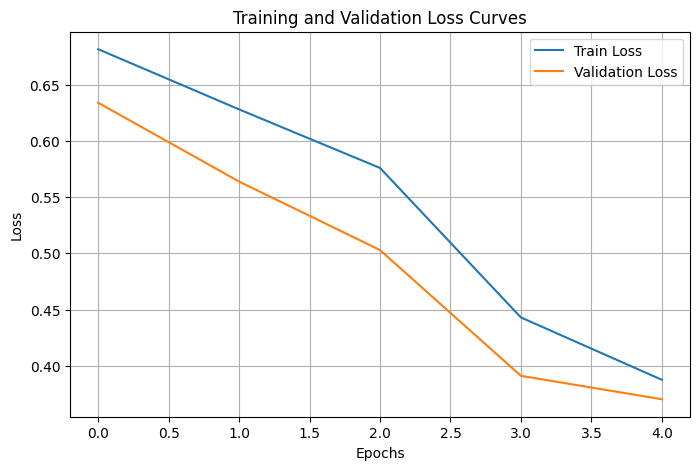

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def predict_sentiment_keras(model, sentence, max_length=200):
    model.eval()
    # Simple word-to-index using the Keras index map
    word_to_id = tf.keras.datasets.imdb.get_word_index()
    tokens = sentence.lower().translate(str.maketrans('', '', string.punctuation)).split()
    seq = [word_to_id.get(w, 2) + 3 for w in tokens]
    seq = [idx if idx < MAX_VOCAB_SIZE else 2 for idx in seq]
    if len(seq) < max_length:
        seq = seq + [0] * (max_length - len(seq))
    else:
        seq = seq[:max_length]
    tensor = torch.LongTensor(seq).unsqueeze(0).to(device)
    with torch.no_grad():
        prediction = torch.sigmoid(model(tensor))
    return prediction.item()

test_review = "This movie was fantastic The acting was great and the plot kept me engaged"
pred_val = predict_sentiment_keras(model, test_review)
print(f"Review: '{test_review}'")
print(f"Predicted Sentiment Score: {pred_val:.4f} ({'Positive' if pred_val > 0.5 else 'Negative'})")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: 'This movie was fantastic The acting was great and the plot kept me engaged'
Predicted Sentiment Score: 0.9479 (Positive)
